## 1. Configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import trackpy as tp
import scienceplots                  
import warnings
from scipy.signal import savgol_filter

tp.quiet()
warnings.filterwarnings('ignore', category=UserWarning, module='trackpy')
warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.style.use(['science', 'no-latex'])
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.3})

MODO = 'equiparticion'       # 'equiparticion' | 'arrastre' (valores de MODO)
VIDEO = "muestratrapada.avi"
T_INICIO_S = 108            # recorte temporal en segundos; None = desde el inicio
T_FIN_S = 145               # None = hasta el final

T_K = 298.15                 # K
RADIO_UM = 1.62              # radio nominal de las esferas
RADIO_UM_ERR = 0.08
ESCALA_UM_PX = 0.0946        # calibración con retículo
ESCALA_UM_PX_ERR = 0.002
ETA_MEDIDA = 2.36            # mPa s, del análisis browniano
ETA_MEDIDA_ERR = 0.30
K_B = 1.380649e-23

CANAL = 'verde'              # 'verde' | 'rojo' | 'azul' | 'gris'
ROI = None                   # (y0, y1, x0, x1); None = automático

# Seguimiento del núcleo brillante. Las posiciones se leen de la figura del
# catálogo, en píxeles de la imagen ya recortada por el ROI.
POSICION_TRAMPA = (635, 537)       # (x, y); None = máximo de rojo menos verde
POSICION_SUCIEDAD = None     # (x, y) de algo adherido y brillante; None = sin
                             # corrección de sigma, y entonces k es cota inferior
MARGEN = 25                  # px del recorte alrededor de cada posición
DIAMETRO_NUCLEO = 9          # impar; tamaño del núcleo brillante
MINMASS_NUCLEO = 300         # umbral de masa del núcleo
MAX_DIST = 8                 # px desde el centro del recorte
MAX_SALTO = 5                # px entre frames consecutivos
DETREND = True               # quita deriva lenta antes de calcular varianzas

# Detección clásica, solo para la partícula libre del método de arrastre.
DIAMETRO = 35                # impar
INVERTIR = True              # partículas oscuras sobre fondo claro
PERCENTIL_MASA = 92
SEARCH_RANGE = 8
MEMORIA = 3
MIN_LARGO = 50
VENTANA_SUAVIZADO = 11       # frames, impar, para Savitzky-Golay
N_PRE_ESCAPE = 10            # frames de la ventana previa al escape
FRAME_ESCAPE = None          # None = automático; si se fija, contado desde K_INI

SALIDA = "figuras_pinza"
FORMATO = 'svg'
DPI = 300
os.makedirs(SALIDA, exist_ok=True)

try:
    import numba                                              # noqa: F401
    ENGINE = 'numba'
except ImportError:
    ENGINE = 'auto'


def guardar(nombre):
    ruta = os.path.join(SALIDA, f"{nombre}.{FORMATO}")
    plt.savefig(ruta, dpi=DPI, bbox_inches='tight')
    return ruta

## 2. Video y ventana temporal

In [2]:
cap = cv2.VideoCapture(VIDEO)
if not cap.isOpened():
    raise IOError(f"No se pudo abrir {VIDEO}")
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
DT = 1.0/FPS
print(f"{VIDEO}: {N_TOTAL} frames, {FPS:.3f} fps, {N_TOTAL/FPS:.1f} s")

# La ventana sirve para descartar los tramos arruinados (la cámara se movió, la
# partícula se escapó antes de tiempo). El tiempo se cuenta desde su primer
# frame y todo lo que sigue trabaja adentro.
K_INI = 0 if T_INICIO_S is None else max(int(round(T_INICIO_S*FPS)), 0)
K_FIN = (N_TOTAL - 1 if T_FIN_S is None
         else min(int(round(T_FIN_S*FPS)), N_TOTAL - 1))
if K_FIN - K_INI < 10:
    raise ValueError("Ventana temporal demasiado corta.")
print(f"ventana: frames {K_INI}-{K_FIN}, {(K_FIN - K_INI + 1)/FPS:.1f} s")


def extraer_canal(frame, canal=CANAL):
    if frame.ndim == 2:
        return frame.astype(np.float32)
    i = {'azul': 0, 'verde': 1, 'rojo': 2}.get(canal)
    g = frame[:, :, i] if i is not None else cv2.cvtColor(frame,
                                                          cv2.COLOR_BGR2GRAY)
    return g.astype(np.float32)


def un_frame_color(k):
    cap = cv2.VideoCapture(VIDEO)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(k))
    ok, fr = cap.read()
    cap.release()
    if not ok:
        raise IOError(f"No se pudo leer el frame {k}")
    return fr


def leer_frames(roi=None):
    """Itera (k, canal) sobre la ventana temporal."""
    cap = cv2.VideoCapture(VIDEO)
    cap.set(cv2.CAP_PROP_POS_FRAMES, K_INI)
    k = K_INI
    while k <= K_FIN:
        ok, frame = cap.read()
        if not ok:
            break
        g = extraer_canal(frame)
        yield k, (g[roi[0]:roi[1], roi[2]:roi[3]] if roi is not None else g)
        k += 1
    cap.release()

muestratrapada.avi: 4166 frames, 22.502 fps, 185.1 s
ventana: frames 2430-3263, 37.1 s


## 3. Región de interés, posición del láser y catálogo

El ROI recorta los bordes del encuadre: los filtros posteriores son  
convoluciones y un borde abrupto genera una respuesta propia.

ROI (5, 1018, 5, 1274) -> 1013x1269 px
láser en (635, 537); trampa en (635, 537)


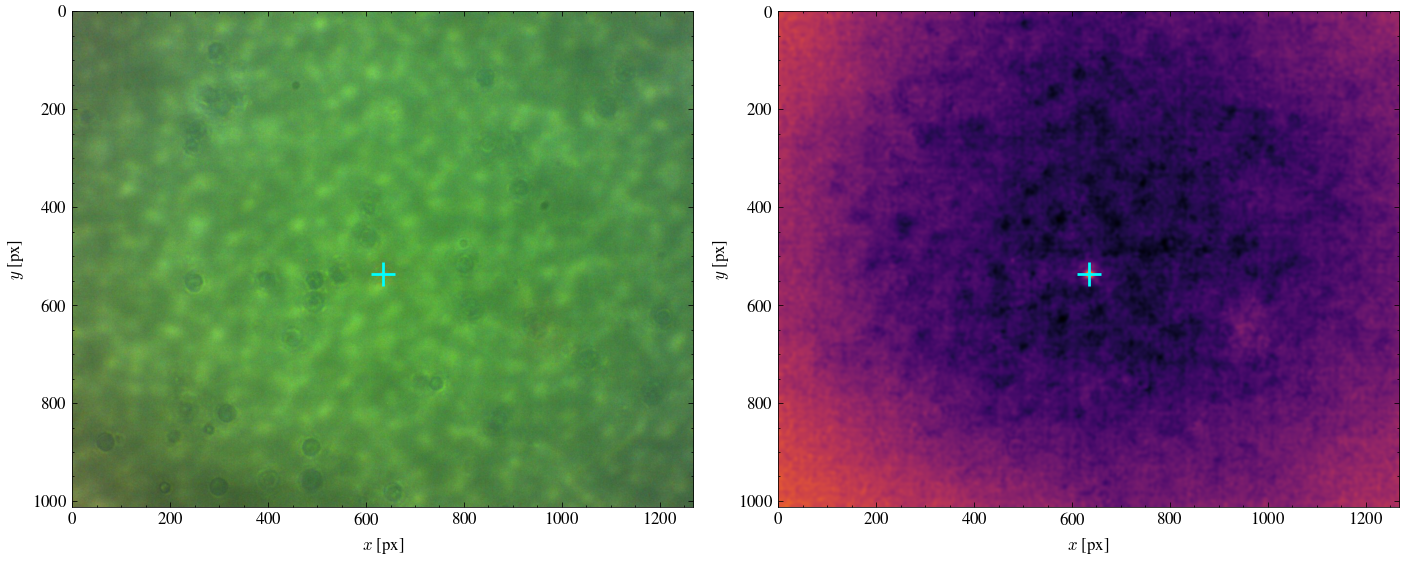

In [3]:
frame_crudo = un_frame_color(K_INI)
img0 = extraer_canal(frame_crudo)
if ROI is None:
    fy = np.where(img0.mean(axis=1) > 30)[0]
    fx = np.where(img0.mean(axis=0) > 30)[0]
    ROI = (int(fy.min()) + 5, int(fy.max()) - 5,
           int(fx.min()) + 5, int(fx.max()) - 5)
print(f"ROI {ROI} -> {ROI[1]-ROI[0]}x{ROI[3]-ROI[2]} px")

rec_color = frame_crudo[ROI[0]:ROI[1], ROI[2]:ROI[3]]

# El láser es rojo: su posición es el máximo de rojo menos verde, que no se
# confunde con los reflejos blancos ni con la iluminación del LED.
realce = cv2.GaussianBlur(rec_color[:, :, 2].astype(float) -
                          rec_color[:, :, 1].astype(float), (0, 0), 3)
y_laser, x_laser = np.unravel_index(np.argmax(realce), realce.shape)
if POSICION_TRAMPA is None:
    POSICION_TRAMPA = (int(x_laser), int(y_laser))
print(f"láser en ({x_laser}, {y_laser}); trampa en {POSICION_TRAMPA}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
ax[0].imshow(rec_color[:, :, ::-1])
ax[0].plot(*POSICION_TRAMPA, '+', color='cyan', ms=16, mew=1.8)
if POSICION_SUCIEDAD is not None:
    ax[0].plot(*POSICION_SUCIEDAD, 'x', color='yellow', ms=14, mew=1.8)
ax[0].set_xlabel('$x$ [px]')
ax[0].set_ylabel('$y$ [px]')
ax[1].imshow(realce, cmap='inferno')
ax[1].plot(x_laser, y_laser, '+', color='cyan', ms=16, mew=1.8)
ax[1].set_xlabel('$x$ [px]')
ax[1].set_ylabel('$y$ [px]')
for a in ax:
    a.grid(False)
plt.tight_layout()
guardar('campo')
plt.show()

## 4. Seguimiento del núcleo brillante

Top-hat morfológico: resta a la imagen su apertura, de modo que elimina todo  
lo que sea más ancho que el elemento estructurante (fondo, halo del láser,  
anillos de difracción) y deja los máximos compactos. Sobre eso se localiza un  
único núcleo por frame.  

Tres filtros, en orden: masa mínima, distancia al centro del recorte y salto  
máximo entre frames consecutivos. El último descarta los cambios de objeto;  
su valor debe quedar muy por encima de la excursión térmica esperada, que para  
una trampa de pocos pN/um es de décimas de píxel, para no recortar la señal.

In [4]:
KERNEL_TH = np.ones((11, 11), np.uint8)


def seguir_nucleo(pos, etiqueta=''):
    """(t, x, y) en s y um del núcleo brillante alrededor de pos."""
    xc, yc = int(pos[0]), int(pos[1])
    filas, masas = [], []
    for k, g in leer_frames(ROI):
        rec = g[yc-MARGEN:yc+MARGEN, xc-MARGEN:xc+MARGEN]
        if rec.shape != (2*MARGEN, 2*MARGEN):
            raise ValueError(f"{pos} está a menos de {MARGEN} px del borde.")
        f = tp.locate(cv2.morphologyEx(rec, cv2.MORPH_TOPHAT, KERNEL_TH),
                      DIAMETRO_NUCLEO, minmass=MINMASS_NUCLEO, invert=False,
                      engine=ENGINE)
        if len(f) == 0:
            continue
        f = f[np.hypot(f['x'] - MARGEN, f['y'] - MARGEN) < MAX_DIST]
        if len(f) == 0:
            continue
        p = f.loc[f['mass'].idxmax()]
        xa, ya = p['x'] + xc - MARGEN, p['y'] + yc - MARGEN
        if filas and np.hypot(xa - filas[-1][1], ya - filas[-1][2]) > MAX_SALTO:
            continue
        filas.append((k, xa, ya))
        masas.append(p['mass'])
    if len(filas) < 10:
        raise ValueError(f"Solo {len(filas)} frames con núcleo en {pos}: "
                         "bajar MINMASS_NUCLEO o revisar la posición.")
    a = np.array(filas, dtype=float)
    n_ventana = K_FIN - K_INI + 1
    print(f"{etiqueta or pos}: {len(a)}/{n_ventana} frames, "
          f"masa mediana {np.median(masas):.0f}")
    return ((a[:, 0] - K_INI)*DT, a[:, 1]*ESCALA_UM_PX, a[:, 2]*ESCALA_UM_PX,
            float(np.median(masas)))


def sin_deriva(z):
    """Quita la deriva lenta. Una deriva de la platina no es ruido termico."""
    if not DETREND or len(z) < 11:
        return z - z.mean()
    w = min(51, (len(z)//2)*2 - 1)
    return z - savgol_filter(z, w, 1)

## 5. Equipartición

trampa: 830/834 frames, masa mediana 526
sin referencia: k queda como cota inferior

N = 830 muestras independientes
rms: x 32.1 nm, y 42.0 nm
k_x = 4.00 +- 0.26 pN/um
k_y = 2.33 +- 0.15 pN/um
anisotropía k_x/k_y = 1.72
tiempo de relajación gamma/k = 23 ms (intervalo entre frames 44 ms)
$x$: varianza 4.00, pozo 4.12 +- 0.27 pN/um, chi2/nu = 1.09
$y$: varianza 2.33, pozo 2.31 +- 0.14 pN/um, chi2/nu = 6.31


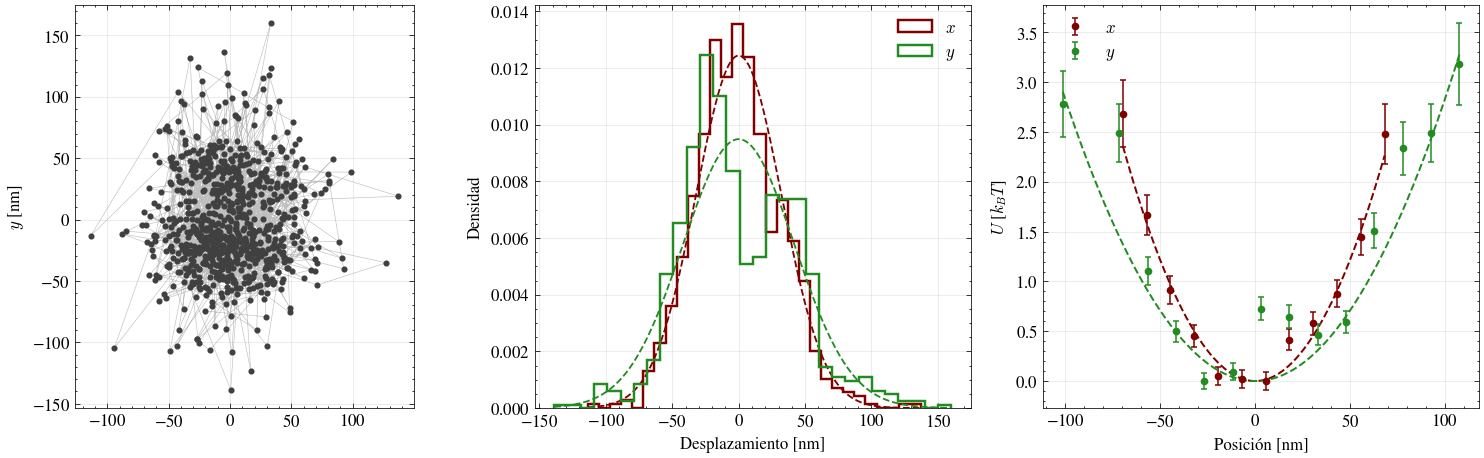

In [6]:
if MODO == 'equiparticion':
    t, x, y, masa_tr = seguir_nucleo(POSICION_TRAMPA, 'trampa')

    # sigma, el ruido de localización del método, se mide sobre algo adherido al
    # vidrio: su dispersión aparente es ruido puro. Entra como
    # <x^2>_medido = <x^2> + sigma^2, de modo que sin corregirlo k sale
    # subestimado. La precisión de localización depende de la relación
    # señal/ruido, así que el sigma de la referencia solo es transferible si su
    # masa es comparable a la del núcleo de la trampa.
    if POSICION_SUCIEDAD is not None:
        _, xs, ys, masa_su = seguir_nucleo(POSICION_SUCIEDAD, 'referencia')
        SIGMA_UM = np.sqrt(0.5*(sin_deriva(xs).var(ddof=1) +
                                sin_deriva(ys).var(ddof=1)))
        print(f"sigma del método: {SIGMA_UM*1e3:.1f} nm = "
              f"{SIGMA_UM/ESCALA_UM_PX:.2f} px")
        if not 0.5 < masa_su/masa_tr < 2:
            print("   masas muy distintas: sigma puede no ser transferible")
    else:
        SIGMA_UM = 0.0
        print("sin referencia: k queda como cota inferior")

    dx, dy = sin_deriva(x), sin_deriva(y)
    var_x = dx.var(ddof=1) - SIGMA_UM**2
    var_y = dy.var(ddof=1) - SIGMA_UM**2
    if min(var_x, var_y) <= 0:
        raise ValueError("Varianza corregida negativa: la referencia fluctúa "
                         "más que la trampa. Revisar POSICION_SUCIEDAD.")

    # Las muestras son independientes: el tiempo de relajación de la trampa,
    # gamma/k, es mucho menor que el intervalo entre frames. La incerteza de una
    # varianza con N muestras independientes es sqrt(2/(N-1)), y la calibración
    # entra al cuadrado.
    kBT = K_B*T_K
    k_x = kBT/(var_x*1e-12)*1e6                       # pN/um
    k_y = kBT/(var_y*1e-12)*1e6
    rel = np.hypot(np.sqrt(2/(len(x) - 1)), 2*ESCALA_UM_PX_ERR/ESCALA_UM_PX)

    print(f"\nN = {len(x)} muestras independientes")
    print(f"rms: x {np.sqrt(var_x)*1e3:.1f} nm, y {np.sqrt(var_y)*1e3:.1f} nm")
    print(f"k_x = {k_x:.2f} +- {k_x*rel:.2f} pN/um")
    print(f"k_y = {k_y:.2f} +- {k_y*rel:.2f} pN/um")
    print(f"anisotropía k_x/k_y = {k_x/k_y:.2f}")
    gamma = 6*np.pi*ETA_MEDIDA*1e-3*RADIO_UM*1e-6
    tau_c = gamma/(0.5*(k_x + k_y)*1e-6)
    print(f"tiempo de relajación gamma/k = {tau_c*1e3:.0f} ms "
          f"(intervalo entre frames {DT*1e3:.0f} ms)")
    if tau_c > DT:
        print("   relajación más lenta que el muestreo: las muestras están "
              "correlacionadas y la incerteza está subestimada")

    fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
    ax[0].plot(dx*1e3, dy*1e3, '-', lw=0.4, color='0.75', zorder=0)
    ax[0].plot(dx*1e3, dy*1e3, 'o', ms=3, color='0.25')
    ax[0].set_ylabel('$y$ [nm]')
    ax[0].set_aspect('equal')

    for d, nom, col in ((dx, '$x$', 'maroon'), (dy, '$y$', 'forestgreen')):
        ax[1].hist(d*1e3, bins=30, histtype='step', lw=1.6, color=col,
                   density=True, label=nom)
        zz = np.linspace(d.min(), d.max(), 200)*1e3
        s = d.std(ddof=1)*1e3
        ax[1].plot(zz, np.exp(-zz**2/(2*s**2))/np.sqrt(2*np.pi*s**2), '--',
                   lw=1.2, color=col)
    ax[1].set_xlabel('Desplazamiento [nm]')
    ax[1].set_ylabel('Densidad')
    ax[1].legend()

    # Pozo de potencial: U = -k_B T ln P. La parábola no se ajusta, se traza con
    # la k que salió de la varianza, de modo que el acuerdo es una verificación.
    for d, k_i, nom, col in ((dx, k_x, '$x$', 'maroon'),
                             (dy, k_y, '$y$', 'forestgreen')):
        cnt, bordes = np.histogram(d*1e3, bins=20)
        c = 0.5*(bordes[1:] + bordes[:-1])
        m = cnt > 5                             # bines con estadística suficiente
        P = cnt[m]/(cnt.sum()*np.diff(bordes)[0])
        U = -np.log(P)
        eU = 1/np.sqrt(cnt[m])                  # error poissoniano de -ln N
        A = (c[m]*1e-9)**2/(2*kBT)
        (pend, orig), cov = np.polyfit(A, U, 1, w=1/eU, cov='unscaled')
        chi2 = np.sum(((U - (pend*A + orig))/eU)**2)/(len(U) - 2)
        print(f"{nom}: varianza {k_i:.2f}, pozo {pend*1e6:.2f} "
              f"+- {np.sqrt(cov[0, 0])*1e6:.2f} pN/um, chi2/nu = {chi2:.2f}")
        ax[2].errorbar(c[m], U - U.min(), yerr=eU, fmt='o', ms=4, color=col,
                       capsize=2, label=nom)
        zz = np.linspace(c[m].min(), c[m].max(), 200)
        ax[2].plot(zz, 0.5*k_i*1e-6*(zz*1e-9)**2/kBT, '--', lw=1.3, color=col)
    ax[2].set_xlabel('Posición [nm]')
    ax[2].set_ylabel(r'$U$ [$k_B T$]')
    ax[2].legend()
    plt.tight_layout()
    guardar('equiparticion')
    plt.show()

    pd.DataFrame({'t_s': t, 'x_um': x, 'y_um': y}).to_csv(
        os.path.join(SALIDA, 'trampa.csv'), index=False)

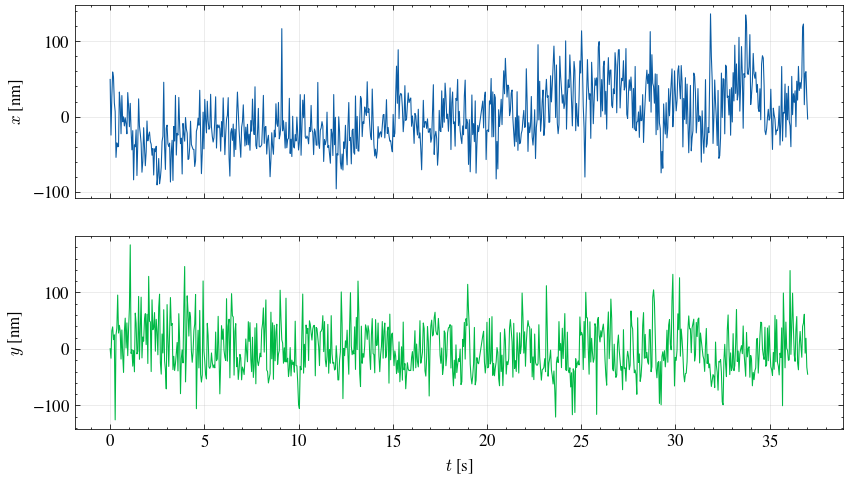

In [23]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(t, (x - x.mean())*1e3, lw=0.7)
ax[1].plot(t, (y - y.mean())*1e3, lw=0.7, color='C1')
ax[0].set_ylabel('$x$ [nm]')
ax[1].set_ylabel('$y$ [nm]')
ax[1].set_xlabel('$t$ [s]')
plt.show()